# Assignment 1 – Option Basics, BSM model

| Task | Points |
| :- | :-: |
| a) Customizable plotter + extra features | 4 |
| b) BSM call pricer returning the greeks | 3 |
| c) BSM pricer for European put | 3 |
| d) Check Put-Call parity | 5 |

**Conventions.** The pricers keep the lecture's signature `(r, T, S0, sigma, K)` and are vectorized in `K`.
Greeks are per unit change of the risk factor (vega per 1.00 change of $\sigma$, rho per 1.00 change of $r$).
Theta is $\partial V / \partial t = -\partial V / \partial T$ per year, the convention of the lecture's formula and of the course library.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

## a) Plotter

All formerly hard-coded settings are now keys of `DEFAULT_LAYOUT` (default values = the lecture's values); a call overrides only what it needs.
The signature `my_plotter(x, y, layout, names)` is unchanged, so the lecture's calls still work.

New features: y label, grid, axis limits, vertical reference lines (e.g. the strike), per-line styles, drawing into an existing subplot (`ax`), saving to file, returning the `Axes`.
Unknown layout keys raise an error instead of being silently ignored. The lecture's version also modified the global `rcParams`; this one has no global side effects.

In [2]:
DEFAULT_LAYOUT = {
    'figsize': (8, 4),
    'title': None, 'title_fontsize': 20, 'title_pad': 30,
    'x_label': None, 'y_label': None, 'label_fontsize': 16, 'label_pad': 20,
    'tick_fontsize': 12, 'legend_fontsize': 16, 'legend_loc': 'best',
    'grid': False, 'x_lim': None, 'y_lim': None,
    'zero_line': True,  # dashed horizontal line at y = 0
    'v_lines': (),      # vertical reference lines, e.g. the strike
}
DEFAULT_LINE_STYLE = {'linestyle': 'solid', 'linewidth': 4}


def my_plotter(x, y, layout: dict = None, names: list[str] = None, styles=None, ax: plt.Axes = None,
               save_path: str = None) -> plt.Axes:
    """
    param x: x values
    param y: one line (sequence of numbers) or several lines (sequence of sequences)
    param layout: dict overriding keys of DEFAULT_LAYOUT
    param names: legend labels, one per line (no legend if None)
    param styles: plt.plot keyword arguments overriding DEFAULT_LINE_STYLE, one dict for all lines or a list of dicts
    param ax: existing Axes to draw into (e.g. a subplot), a new figure is created if None
    param save_path: if given, the figure is saved to this file
    """
    layout = layout or {}
    unknown = set(layout) - set(DEFAULT_LAYOUT)
    if unknown:
        raise ValueError(f'Unknown layout keys: {sorted(unknown)}')
    layout = {**DEFAULT_LAYOUT, **layout}

    lines = [y] if np.ndim(y[0]) == 0 else list(y)
    if names is not None and len(names) != len(lines):
        raise ValueError('Length of names is not matching with number of plotted y lists.')
    if styles is None or isinstance(styles, dict):
        styles = [styles or {}] * len(lines)
    elif len(styles) != len(lines):
        raise ValueError('Length of styles is not matching with number of plotted y lists.')

    new_figure = ax is None
    if new_figure:
        _, ax = plt.subplots(figsize=layout['figsize'])
    for i, (line, style) in enumerate(zip(lines, styles)):
        ax.plot(x, line, label=None if names is None else names[i], **{**DEFAULT_LINE_STYLE, **style})

    if layout['zero_line']:
        ax.axhline(0, linestyle='--', color='black', linewidth=1)
    for v in layout['v_lines']:
        ax.axvline(v, linestyle=':', color='grey', linewidth=1.5)
    if layout['title'] is not None:
        ax.set_title(layout['title'], fontsize=layout['title_fontsize'], pad=layout['title_pad'])
    if layout['x_label'] is not None:
        ax.set_xlabel(layout['x_label'], fontsize=layout['label_fontsize'], labelpad=layout['label_pad'])
    if layout['y_label'] is not None:
        ax.set_ylabel(layout['y_label'], fontsize=layout['label_fontsize'], labelpad=layout['label_pad'])
    ax.tick_params(labelsize=layout['tick_fontsize'])
    if layout['x_lim'] is not None:
        ax.set_xlim(layout['x_lim'])
    if layout['y_lim'] is not None:
        ax.set_ylim(layout['y_lim'])
    if layout['grid']:
        ax.grid(alpha=0.4)
    if names is not None:
        ax.legend(fontsize=layout['legend_fontsize'], loc=layout['legend_loc'])

    if new_figure:
        plt.tight_layout()
        if save_path is not None:
            ax.figure.savefig(save_path, dpi=150)
        plt.show()
    return ax

The lecture's call, unchanged:

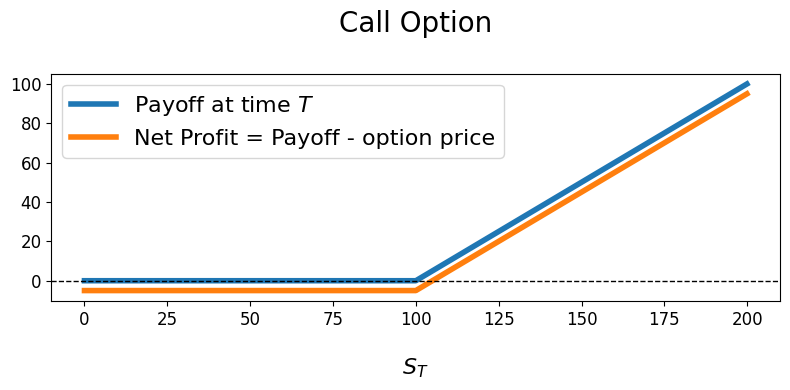

In [3]:
strike = 100
x_stock_price = np.arange(0, 2 * strike, 0.1)
call_price, put_price = 5, 8
y_call_payoff = np.maximum(x_stock_price - strike, 0.0)
y_put_payoff = np.maximum(strike - x_stock_price, 0.0)

my_plotter(x_stock_price, [y_call_payoff, y_call_payoff - call_price], layout={'title': 'Call Option', 'x_label': '$S_{T}$'},
           names=['Payoff at time $T$', 'Net Profit = Payoff - option price']);

Customized: y label, grid, strike marker, per-line styles. (The net profit uses the put price; the lecture notebook subtracted the call price here.)

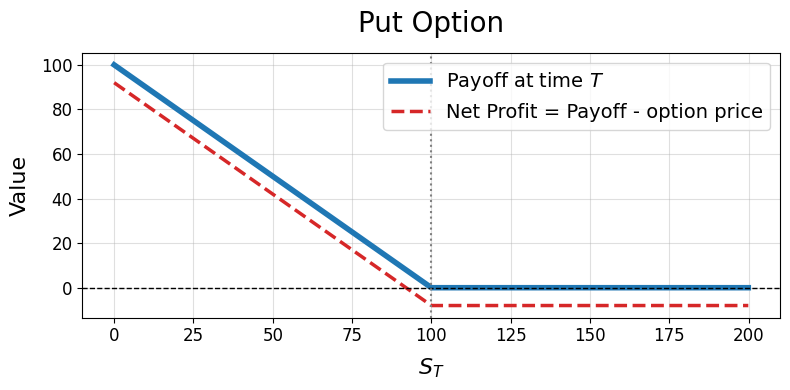

In [4]:
my_plotter(x_stock_price, [y_put_payoff, y_put_payoff - put_price],
           layout={'title': 'Put Option', 'x_label': '$S_{T}$', 'y_label': 'Value', 'title_pad': 15, 'label_pad': 8,
                   'legend_fontsize': 14, 'grid': True, 'v_lines': [strike]},
           names=['Payoff at time $T$', 'Net Profit = Payoff - option price'],
           styles=[{'color': 'tab:blue'}, {'color': 'tab:red', 'linestyle': '--', 'linewidth': 2.5}]);

## b) BSM call pricer with greeks

Same signature as in the lecture; with `greeks=True` it returns a dict with the price and the greeks.
Fix compared to the lecture: the return line used the global `K_vec` instead of the parameter `K` (it only worked because a global with that name existed).

With $\varphi$ the standard normal density and $DF = e^{-rT}$:

| | Call | Put |
| :- | :- | :- |
| Price | $S_0 N(d_1) - K\,DF\,N(d_2)$ | $K\,DF\,N(-d_2) - S_0 N(-d_1)$ |
| $\Delta$ | $N(d_1)$ | $N(d_1) - 1 = -N(-d_1)$ |
| $\Gamma$ | $\varphi(d_1) / (S_0 \sigma \sqrt{T})$ | same |
| $\mathcal{V}$ | $S_0\,\varphi(d_1)\sqrt{T}$ | same |
| $\Theta$ | $-S_0\varphi(d_1)\sigma/(2\sqrt{T}) - rK\,DF\,N(d_2)$ | $-S_0\varphi(d_1)\sigma/(2\sqrt{T}) + rK\,DF\,N(-d_2)$ |
| $\rho$ | $K T\,DF\,N(d_2)$ | $-K T\,DF\,N(-d_2)$ |

In [5]:
GREEKS = ('delta', 'gamma', 'vega', 'theta', 'rho')


def _bsm_inputs(r, T, S0, sigma, K):
    """Strike array, d1, d2 and discount factor."""
    assert sigma > 0 and T > 0
    K = np.atleast_1d(np.asarray(K, dtype=float))
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return K, d1, d1 - sigma * np.sqrt(T), np.exp(-r * T)


def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K, greeks: bool = False):
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    param greeks: if True, returns a dict with 'price' and the greeks, otherwise the price array
    """
    K, d1, d2, df = _bsm_inputs(r, T, S0, sigma, K)
    price = S0 * norm.cdf(d1) - K * df * norm.cdf(d2)
    if not greeks:
        return price
    return {
        'price': price,
        'delta': norm.cdf(d1),
        'gamma': norm.pdf(d1) / (S0 * sigma * np.sqrt(T)),
        'vega': S0 * norm.pdf(d1) * np.sqrt(T),
        'theta': -S0 * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) - r * K * df * norm.cdf(d2),
        'rho': K * T * df * norm.cdf(d2),
    }

## c) BSM put pricer

In [6]:
def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K, greeks: bool = False):
    """Black-Scholes pricer of European put option on non-dividend-paying stock, parameters as for the call."""
    K, d1, d2, df = _bsm_inputs(r, T, S0, sigma, K)
    price = K * df * norm.cdf(-d2) - S0 * norm.cdf(-d1)
    if not greeks:
        return price
    return {
        'price': price,
        'delta': -norm.cdf(-d1),  # = N(d1) - 1, without cancellation for deep out-of-the-money puts
        'gamma': norm.pdf(d1) / (S0 * sigma * np.sqrt(T)),
        'vega': S0 * norm.pdf(d1) * np.sqrt(T),
        'theta': -S0 * norm.pdf(d1) * sigma / (2 * np.sqrt(T)) + r * K * df * norm.cdf(-d2),
        'rho': -K * T * df * norm.cdf(-d2),
    }

### Check of the greeks against finite differences

Each analytic greek is compared with a central finite difference of the price (bump and revaluation; for theta the maturity is bumped and the sign flipped).

In [7]:
def finite_difference_greeks(pricer, r, T, S0, sigma, K, h=1e-4):
    def price(**bump):
        return pricer(**{'r': r, 'T': T, 'S0': S0, 'sigma': sigma, 'K': K, **bump})

    dS = h * S0
    return {
        'delta': (price(S0=S0 + dS) - price(S0=S0 - dS)) / (2 * dS),
        'gamma': (price(S0=S0 + dS) - 2 * price() + price(S0=S0 - dS)) / dS**2,
        'vega': (price(sigma=sigma + h) - price(sigma=sigma - h)) / (2 * h),
        'theta': -(price(T=T + h) - price(T=T - h)) / (2 * h),
        'rho': (price(r=r + h) - price(r=r - h)) / (2 * h),
    }


market = dict(r=0.05, T=1.0, S0=20.0, sigma=0.3, K=np.arange(10, 30, 0.5))  # the lecture's example
check = {}
for name, pricer in (('call', black_scholes_eur_call), ('put', black_scholes_eur_put)):
    analytic, numeric = pricer(**market, greeks=True), finite_difference_greeks(pricer, **market)
    check[f'{name}: max |greek|'] = [np.max(np.abs(analytic[g])) for g in GREEKS]
    check[f'{name}: max |analytic - FD|'] = [np.max(np.abs(analytic[g] - numeric[g])) for g in GREEKS]
pd.DataFrame(check, index=GREEKS)

,call: max |greek|,call: max |analytic - FD|,put: max |greek|,put: max |analytic - FD|
delta,0.995695,5.921309e-09,0.836175,5.920755e-09
gamma,0.066490,1.852795e-09,0.066490,2.949300e-09
vega,7.978841,2.131814e-07,7.978841,2.131814e-07
theta,1.626397,1.546969e-09,0.678079,1.554792e-09
rho,11.919433,9.921682e-08,25.241863,1.263175e-07


The differences are 7–9 orders of magnitude below the greeks (truncation and rounding error of the finite differences): the formulas and their signs are correct.

Price and greeks as a function of the strike, the lecture's market ($S_0 = 20$, $\sigma = 0.3$, $r = 0.05$):

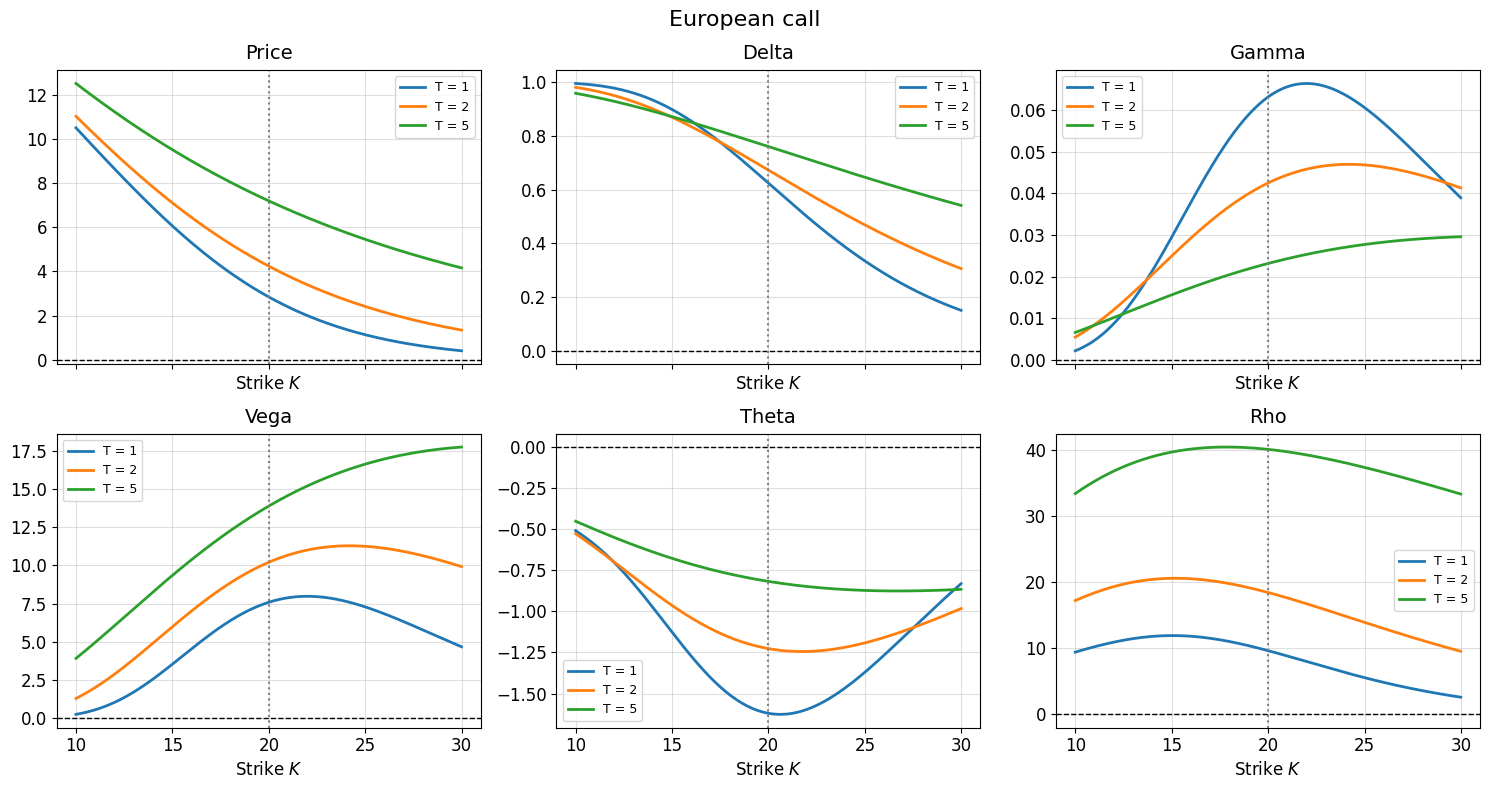

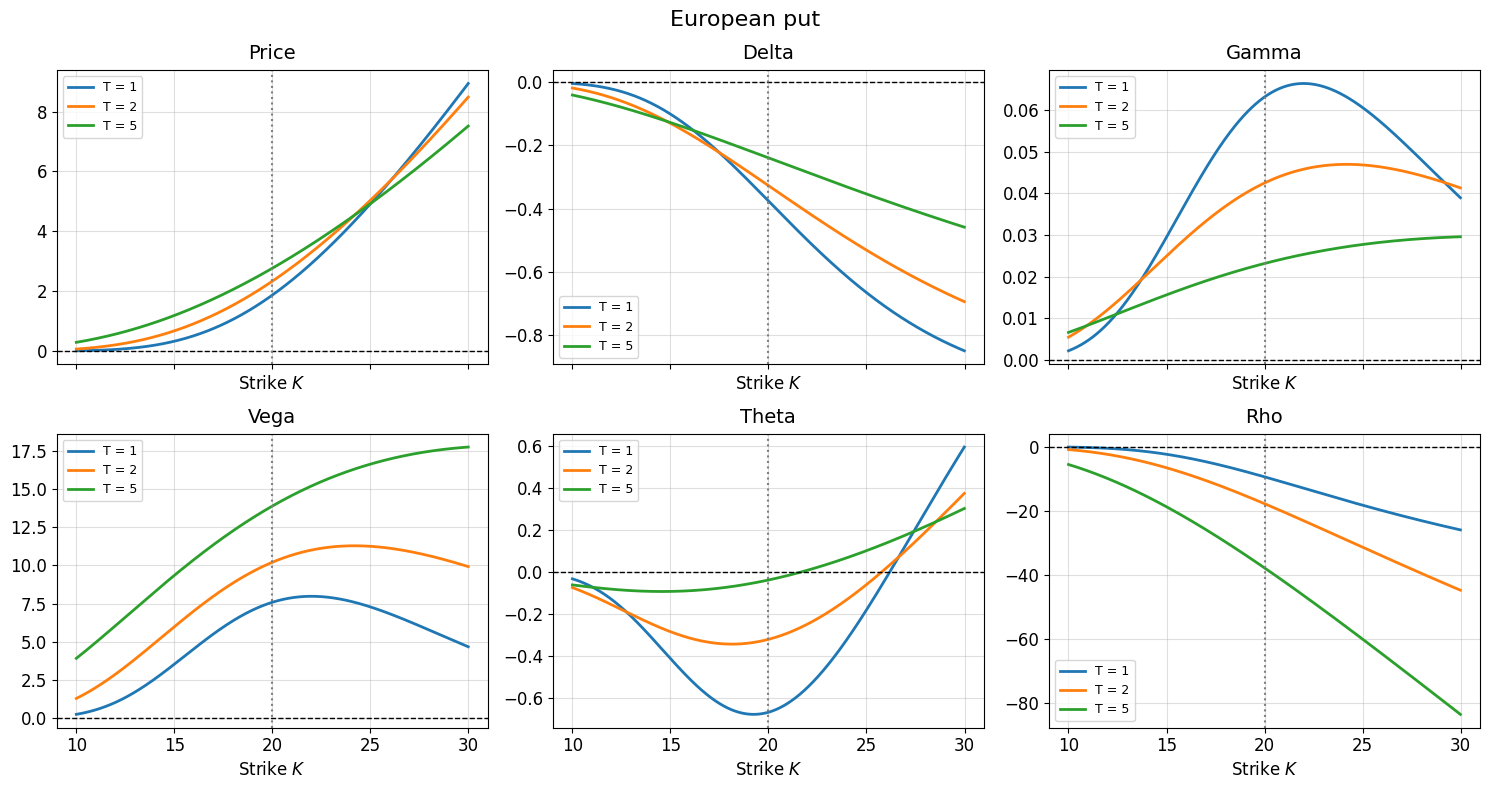

In [8]:
def plot_price_and_greeks(pricer, title, r=0.05, S0=20.0, sigma=0.3, maturities=(1.0, 2.0, 5.0)):
    strikes = np.arange(10, 30, 0.01)
    results = [pricer(r, T, S0, sigma, strikes, greeks=True) for T in maturities]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
    for ax, measure in zip(axes.flat, ('price',) + GREEKS):
        my_plotter(strikes, [res[measure] for res in results], names=[f'T = {T:g}' for T in maturities], ax=ax,
                   styles={'linewidth': 2},
                   layout={'title': measure.capitalize(), 'x_label': 'Strike $K$', 'title_fontsize': 14,
                           'label_fontsize': 12, 'legend_fontsize': 9, 'title_pad': 8, 'label_pad': 4,
                           'grid': True, 'v_lines': [S0]})
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


plot_price_and_greeks(black_scholes_eur_call, 'European call')
plot_price_and_greeks(black_scholes_eur_put, 'European put')

## d) Put-Call parity

$$ c - p = S_0 - K e^{-rT} $$

Long call + short put has the payoff $S_T - K$ in every scenario, so it must be worth the same as a long forward (static replication, no model needed).
Differentiating both sides gives the parity of the greeks:

| | $\Delta_c - \Delta_p$ | $\Gamma_c - \Gamma_p$ | $\mathcal{V}_c - \mathcal{V}_p$ | $\Theta_c - \Theta_p$ | $\rho_c - \rho_p$ |
| :- | :-: | :-: | :-: | :-: | :-: |
| Expected | $1$ | $0$ | $0$ | $-rK e^{-rT}$ | $K T e^{-rT}$ |

Check on the lecture's market first:

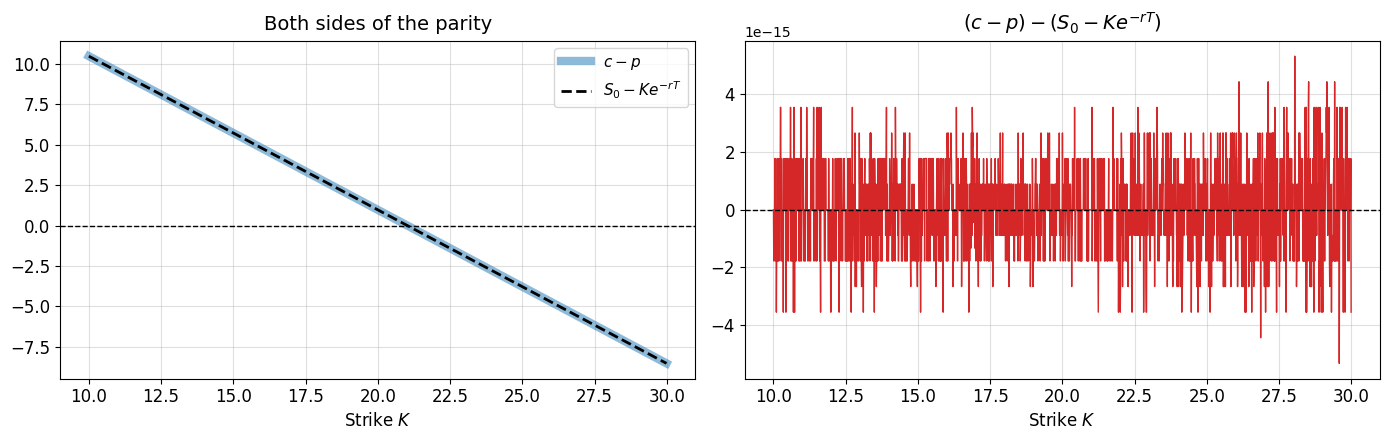

In [9]:
r, T, S0, sigma = 0.05, 1.0, 20.0, 0.3
strikes = np.arange(10, 30, 0.01)
lhs = black_scholes_eur_call(r, T, S0, sigma, strikes) - black_scholes_eur_put(r, T, S0, sigma, strikes)
rhs = S0 - strikes * np.exp(-r * T)

small = {'title_fontsize': 14, 'label_fontsize': 12, 'legend_fontsize': 11, 'title_pad': 8, 'label_pad': 4, 'grid': True}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
my_plotter(strikes, [lhs, rhs], names=['$c - p$', '$S_0 - K e^{-rT}$'], ax=axes[0],
           styles=[{'linewidth': 6, 'alpha': 0.5}, {'linewidth': 2, 'linestyle': '--', 'color': 'black'}],
           layout={'title': 'Both sides of the parity', 'x_label': 'Strike $K$', **small})
my_plotter(strikes, lhs - rhs, ax=axes[1], styles={'linewidth': 1, 'color': 'tab:red'},
           layout={'title': '$(c - p) - (S_0 - K e^{-rT})$', 'x_label': 'Strike $K$', **small})
plt.tight_layout()
plt.show()

Then systematically for the price and all greeks, on every combination of
$S_0 \in \{50, 100, 150\}$, $K/S_0 \in \{0.2, 0.25, \dots, 3.0\}$, $T \in \{0.1, 0.5, 1, 2, 5, 10\}$, $\sigma \in \{0.05, 0.2, 0.5, 1\}$, $r \in \{-0.01, 0, 0.03, 0.1\}$
(288 markets × 57 strikes = 16 416 call–put pairs):

In [10]:
def parity_rhs(measure, r, T, S0, K):
    df = np.exp(-r * T)
    return {'price': S0 - K * df, 'delta': 1.0, 'gamma': 0.0, 'vega': 0.0, 'theta': -r * K * df, 'rho': K * T * df}[measure]


measures = ('price',) + GREEKS
max_error = dict.fromkeys(measures, 0.0)
for S0_, T_, sigma_, r_ in product([50.0, 100.0, 150.0], [0.1, 0.5, 1.0, 2.0, 5.0, 10.0], [0.05, 0.2, 0.5, 1.0],
                                   [-0.01, 0.0, 0.03, 0.1]):
    K_ = S0_ * np.arange(0.2, 3.01, 0.05)
    call = black_scholes_eur_call(r_, T_, S0_, sigma_, K_, greeks=True)
    put = black_scholes_eur_put(r_, T_, S0_, sigma_, K_, greeks=True)
    for m in measures:
        error = np.max(np.abs(call[m] - put[m] - parity_rhs(m, r_, T_, S0_, K_)))
        max_error[m] = max(max_error[m], error)
pd.Series(max_error, name='max |error| over all 16 416 pairs').to_frame()

,max |error| over all 16 416 pairs
price,1.136868e-13
delta,0.000000e+00
gamma,0.000000e+00
vega,0.000000e+00
theta,1.243450e-14
rho,9.094947e-13


### Conclusion

* In the BSM model the parity holds **exactly** for the price and for every greek: the largest deviation is $< 10^{-12}$, i.e. floating point rounding.
* It holds for every $\sigma$, because the right-hand side does not contain $\sigma$: the parity is a model-independent no-arbitrage relation.
  Consequently a call and a put with the same strike and expiry must have the same implied volatility.

**On real market prices** the parity holds only approximately:
* bid-ask spreads and transaction costs turn the equality into a no-arbitrage band;
* dividends: $c - p = S_0 - PV(\text{div}) - K e^{-rT}$;
* most single-stock options are American, for which only $S_0 - K \le C - P \le S_0 - K e^{-rT}$ holds (no dividends);
* funding and stock borrowing costs differ from a single risk-free rate.

In practice the parity is used the other way round: the forward (equivalently, the implied dividend or funding rate) is backed out from quoted call and put prices.